In [ ]:
import gc
import pathlib
import time
import warnings

import marimo as mo
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
from phyloframe import legacy as pfl
import polars as pl
import seaborn as sns
from teeplot import teeplot as tp
from watermark import watermark

from pylib import osf_fetch

warnings.filterwarnings("ignore", category=DeprecationWarning)

# one run per p2p setting, by OSF slug: the seed with the most p2p
# traffic, and a seed with p2p off
RUNS = {"p2p 1/2000": "yjaqh", "p2p off": "nqc5v"}
RUN_PALETTE = {"p2p 1/2000": "#CC79A7", "p2p off": "#6E6E6E"}
# sister clades count as far apart beyond this distance (PEs), and as
# spatially compact if each one's leaves lie within this rms radius
FAR_PES = 50
COMPACT_PES = 5
# partner-alignment radii (PEs) and number of random partner maps for
# the permutation null
PARTNER_RADII = (3, 5)
NUM_NULL_MAPS = 50
SEED = 1

In [ ]:
def make_partner_map(seed, num_rows, num_cols):
    """Each PE's p2p partner (flat index row * num_cols + col; -1 if
    unpaired), as `p2p_make_partner_edgelists` in wse-async-ga pairs PEs
    for a full grid: a random permutation of PEs under `np.random.seed`,
    paired off consecutively."""
    _state = np.random.get_state()
    np.random.seed(seed)
    _tiles = np.random.permutation(num_rows * num_cols)
    np.random.set_state(_state)
    _pairs = _tiles[: len(_tiles) // 2 * 2].reshape(-1, 2)
    partner = np.full(num_rows * num_cols, -1, dtype=np.int64)
    partner[_pairs[:, 0]] = _pairs[:, 1]
    partner[_pairs[:, 1]] = _pairs[:, 0]
    return partner

In [ ]:
def nearest_partner_distance(
    r1, c1, r2, c2, partner, num_rows, num_cols, radius
):
    """For each pair of locations, the distance from (r2, c2) to the nearest
    p2p partner of any PE within `radius` (square) of (r1, c1)."""
    best = np.full(len(r1), np.inf)
    for _dr in range(-radius, radius + 1):
        for _dc in range(-radius, radius + 1):
            _rr, _cc = r1 + _dr, c1 + _dc
            _ok = (_rr >= 0) & (_rr < num_rows) & (_cc >= 0) & (_cc < num_cols)
            _pp = partner[np.where(_ok, _rr * num_cols + _cc, 0)]
            _pr, _pc = np.divmod(np.where(_pp >= 0, _pp, 0), num_cols)
            best = np.minimum(
                best,
                np.where(
                    _ok & (_pp >= 0), np.hypot(_pr - r2, _pc - c2), np.inf
                ),
            )
    return best

In [ ]:
def count_partner_hits(sisters, partner, num_rows, num_cols, radius):
    """Number of sister clade pairs whose locations are linked by a p2p
    partnership, within `radius` of each, in either direction."""
    _r1, _c1, _r2, _c2 = (
        sisters[_k].to_numpy() for _k in ("row_a", "col_a", "row_b", "col_b")
    )
    _best = np.minimum(
        nearest_partner_distance(
            _r1, _c1, _r2, _c2, partner, num_rows, num_cols, radius
        ),
        nearest_partner_distance(
            _r2, _c2, _r1, _c1, partner, num_rows, num_cols, radius
        ),
    )
    return _best <= radius

In [ ]:
def prep_phylogeny(data_path):
    """Load a no-collapse minified phylogeny, drop layer 0 (the initial
    population), prune, and collapse unifurcations."""
    _raw = (
        pl.read_parquet(
            data_path,
            columns=[
                "ancestor_offset",
                "origin_time",
                "clade_size",
                "row",
                "col",
                "group_id_kdtree",
            ],
        )
        .with_row_index("id")
        .with_columns(
            pl.col("id").cast(pl.Int64),
            ancestor_id=(
                pl.col("id").cast(pl.Int64)
                - pl.col("ancestor_offset").cast(pl.Int64)
            ),
        )
        .drop("ancestor_offset")
        .to_pandas()
    )
    _raw["origin_time"] = _raw["origin_time"].fillna(-1).astype(float)
    _is_genome = _raw["clade_size"] > 0
    assert (_raw.loc[_is_genome, "clade_size"] == 1).all(), "no-collapse"
    phylo = (
        _raw.drop(columns="clade_size")
        .assign(extant=_is_genome & (_raw["origin_time"] >= 0))
        .pipe(pfl.alifestd_to_working_format, mutate=True)
        .pipe(pfl.alifestd_prune_extinct_lineages_asexual, mutate=True)
        .pipe(pfl.alifestd_collapse_unifurcations, mutate=True)
        .pipe(pfl.alifestd_to_working_format, mutate=True)
        .pipe(pfl.alifestd_mark_leaves, mutate=True)
        .reset_index(drop=True)
    )
    del _raw
    assert (phylo["is_leaf"] == phylo["extant"]).all()
    assert (phylo["id"] == np.arange(len(phylo))).all()
    return phylo.drop(columns="extant")

In [ ]:
def tabulate_sisters(phylo):
    """For every node with exactly two children, the two child clades'
    leaf centroids, rms spatial spreads, and sizes, and the parent's age
    (time from its origin to its latest leaf)."""
    _n = len(phylo)
    _anc = phylo["ancestor_id"].to_numpy()
    _nonroot = _anc != np.arange(_n)
    _leaf = phylo["is_leaf"].to_numpy()
    _ot = phylo["origin_time"].to_numpy()
    _row = np.where(_leaf, phylo["row"].to_numpy(dtype=float), 0.0)
    _col = np.where(_leaf, phylo["col"].to_numpy(dtype=float), 0.0)
    _sums = {
        "n": _leaf.astype(float),
        "r": _row,
        "c": _col,
        "sq": _row**2 + _col**2,
    }
    _latest = np.where(_leaf, _ot, -np.inf)
    _depth = (
        phylo[["id", "ancestor_id"]]
        .pipe(pfl.alifestd_mark_node_depth_asexual)["node_depth"]
        .to_numpy()
    )
    # accumulate leaf sums up the tree, deepest nodes first
    for _d in range(_depth.max(), 0, -1):
        _idx = np.flatnonzero(_depth == _d)
        for _v in _sums.values():
            np.add.at(_v, _anc[_idx], _v[_idx])
        np.maximum.at(_latest, _anc[_idx], _latest[_idx])
    _cr, _cc = _sums["r"] / _sums["n"], _sums["c"] / _sums["n"]
    _spread = np.sqrt(
        np.maximum(_sums["sq"] / _sums["n"] - _cr**2 - _cc**2, 0.0)
    )
    _num_children = np.bincount(_anc[_nonroot], minlength=_n)
    _kids = np.flatnonzero(_nonroot & (_num_children[_anc] == 2))
    _by_parent = (
        pd.DataFrame({"parent": _anc[_kids], "kid": _kids})
        .sort_values(["parent", "kid"])
        .groupby("parent")["kid"]
    )
    _a, _b = _by_parent.first(), _by_parent.last()
    _parent = _a.index.to_numpy()
    _a, _b = _a.to_numpy(), _b.to_numpy()
    sisters = pd.DataFrame(
        {
            "age": _latest[_parent] - _ot[_parent],
            "separation": np.hypot(_cr[_a] - _cr[_b], _cc[_a] - _cc[_b]),
            "row_a": np.rint(_cr[_a]).astype(np.int64),
            "col_a": np.rint(_cc[_a]).astype(np.int64),
            "row_b": np.rint(_cr[_b]).astype(np.int64),
            "col_b": np.rint(_cc[_b]).astype(np.int64),
            "spread_a": _spread[_a],
            "spread_b": _spread[_b],
            "size": _sums["n"][_parent],
            "is_cherry": (_sums["n"][_a] == 1) & (_sums["n"][_b] == 1),
        },
    )
    return sisters

In [ ]:
mo.md(f"""
```Text
{watermark(
    current_date=True,
    iso8601=True,
    machine=True,
    updated=True,
    python=True,
    iversions=True,
    globals_=globals(),
)}
```
""")

```Text
Last updated: 2026-11-10T17:56:47.349899+00:00

Python implementation: CPython
Python version       : 3.10.22
IPython version      : 7.31.1

Compiler    : GCC 13.3.0
OS          : Linux
Release     : 7.0.0-1017-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 4
Architecture: 64bit

matplotlib: 3.10.9
pandas    : 2.2.3
marimo    : 0.23.2
phyloframe: 0.12.2
polars    : 1.36.1
teeplot   : 1.4.2
seaborn   : 0.13.2
numpy     : 2.1.2

```

In [ ]:
mo.md(f"""
# MLS Individual-host Spectra, Full-grid k-d Tree Fossils with Point-to-point Migration: Evidence of Long-distance Migration

Looks for phylogenetic evidence of long-distance migration in runs with point-to-point (p2p) migration.

Data were generated by [`wse-async-ga` `wsclust/2026-11-09-mls-indiv-spectra-fullgrid-fossils-kdtree-p2p`](https://github.com/mmore500/wse-async-ga/tree/8e1b7dc/wsclust/2026-11-09-mls-indiv-spectra-fullgrid-fossils-kdtree-p2p) (in [mmore500/wse-async-ga#98](https://github.com/mmore500/wse-async-ga/pull/98)), a copy of `2026-11-05-mls-indiv-spectra-fullgrid-fossils-kdtree` that sweeps the per-cycle p2p send probability (off, 1/200,000, 1/20,000, and 1/2,000).
This notebook compares two full-grid runs of genome flavor `genome_mlsindivspectra_2026_11_03`, both hosted on OSF: {", ".join(f"<https://osf.io/{slug}> ({run})" for run, slug in RUNS.items())}.
The p2p run is the seed with the most p2p traffic.

With p2p on, each PE is paired with one partner PE chosen at random across the whole grid (pairs are reciprocal).
Each cycle, a PE sends a genome to its partner with probability 1/2,000; the partner's population takes it in as an immigrant, overwriting a random member.
Ordinary migration between neighboring PEs runs as usual.
The partner pairing is a seeded random permutation of PEs, so this notebook regenerates it from each run's global seed.

Both files are k-d tree group samples (`07-minify-phylo-kdtree`): about 4M fossil genomes from a few spatially compact patches of the grid, reconstructed with hstrat's empirical-Bayes origin times and minified without collapsing, so every sampled genome is its own leaf.

If p2p migrants found lineages that persist, some closely related genomes should be found far apart, and in particular, near PEs that are p2p partners.
So, this notebook tests:

1. the spatial distance between the two leaves of each cherry (two-leaf clade), and between the two child clades of each node, by the node's age; and
2. whether far-apart sister clades sit on p2p partner PEs more often than chance, against a permutation null of random partner maps.
""")

# MLS Individual-host Spectra, Full-grid k-d Tree Fossils with Point-to-point Migration: Evidence of Long-distance Migration

Looks for phylogenetic evidence of long-distance migration in runs with point-to-point (p2p) migration.

Data were generated by [`wse-async-ga` `wsclust/2026-11-09-mls-indiv-spectra-fullgrid-fossils-kdtree-p2p`](https://github.com/mmore500/wse-async-ga/tree/8e1b7dc/wsclust/2026-11-09-mls-indiv-spectra-fullgrid-fossils-kdtree-p2p) (in [mmore500/wse-async-ga#98](https://github.com/mmore500/wse-async-ga/pull/98)), a copy of `2026-11-05-mls-indiv-spectra-fullgrid-fossils-kdtree` that sweeps the per-cycle p2p send probability (off, 1/200,000, 1/20,000, and 1/2,000).
This notebook compares two full-grid runs of genome flavor `genome_mlsindivspectra_2026_11_03`, both hosted on OSF: <https://osf.io/yjaqh> (p2p 1/2000), <https://osf.io/nqc5v> (p2p off).
The p2p run is the seed with the most p2p traffic.

With p2p on, each PE is paired with one partner PE chosen at random across the whole grid (pairs are reciprocal).
Each cycle, a PE sends a genome to its partner with probability 1/2,000; the partner's population takes it in as an immigrant, overwriting a random member.
Ordinary migration between neighboring PEs runs as usual.
The partner pairing is a seeded random permutation of PEs, so this notebook regenerates it from each run's global seed.

Both files are k-d tree group samples (`07-minify-phylo-kdtree`): about 4M fossil genomes from a few spatially compact patches of the grid, reconstructed with hstrat's empirical-Bayes origin times and minified without collapsing, so every sampled genome is its own leaf.

If p2p migrants found lineages that persist, some closely related genomes should be found far apart, and in particular, near PEs that are p2p partners.
So, this notebook tests:

1. the spatial distance between the two leaves of each cherry (two-leaf clade), and between the two child clades of each node, by the node's age; and
2. whether far-apart sister clades sit on p2p partner PEs more often than chance, against a permutation null of random partner maps.

## Get Data

In [ ]:
_cols = [
    "config",
    "genomeFlavor",
    "globalSeed",
    "nRow",
    "nCol",
    "nRowSubgrid",
    "nColSubgrid",
    "nCycle",
    "tilePopSize",
    "ASYNC_GA_P2P_SEND_PROBABILITY",
    "kdtree_num_groups",
]
config_df = pl.concat(
    [
        pl.scan_parquet(osf_fetch(_slug))
        .filter(pl.col("clade_size") > 0)
        .select(_cols)
        .head(1)
        .collect()
        .with_columns(run=pl.lit(_run))
        for _run, _slug in RUNS.items()
    ],
    how="diagonal_relaxed",
)
assert (config_df["nColSubgrid"] == 0).all(), "expected full grid"
config_df.to_pandas().set_index("run").T

downloading https://osf.io/yjaqh/download -> /tmp/yjaqh
size: 72985298 bytes
downloading https://osf.io/nqc5v/download -> /tmp/nqc5v
size: 73330605 bytes


run,p2p 1/2000,p2p off
config,flavor=genome_mlsindivspectra_2026_11_03+subgrid=0+txscale=0.5+p2p=0.0005+seed=1113,flavor=genome_mlsindivspectra_2026_11_03+subgrid=0+txscale=0.5+p2p=0.0+seed=1110
genomeFlavor,genome_mlsindivspectra_2026_11_03,genome_mlsindivspectra_2026_11_03
globalSeed,1113,1110
nRow,1170,1170
nCol,755,755
...,...,...
nColSubgrid,0,0
nCycle,4000,4000
tilePopSize,1133,1133
ASYNC_GA_P2P_SEND_PROBABILITY,0.0005,0.0


## Analyze Runs

Each run's phylogeny is loaded, fossil layer 0 (the initial population) dropped, lineages without retained leaves pruned, and unifurcations collapsed.
Then, for every node with exactly two children, the two child clades' leaf centroids and spatial spreads are tabulated, with the node's age (time from its origin to its latest leaf).
The phylogeny is then discarded to bound memory.

In [ ]:
_sisters, _pes, _summaries = [], [], []
partner_maps = {}
for _cfg in config_df.iter_rows(named=True):
    _run = _cfg["run"]
    _start = time.time()
    _phylo = prep_phylogeny(osf_fetch(RUNS[_run]))
    _leaves = _phylo.loc[_phylo["is_leaf"]].astype(
        {"row": int, "col": int}
    )
    _pes.append(
        _leaves.groupby(["row", "col"])
        .size()
        .rename("num_genomes")
        .reset_index()
        .assign(run=_run)
    )
    _sisters.append(tabulate_sisters(_phylo).assign(run=_run))
    partner_maps[_run] = make_partner_map(
        _cfg["globalSeed"], _cfg["nRow"], _cfg["nCol"]
    )
    _summaries.append(
        {
            "run": _run,
            "num_nodes": len(_phylo),
            "num_leaves": len(_leaves),
            "num_roots": int(
                (_phylo["ancestor_id"] == _phylo["id"]).sum()
            ),
            "num_kdtree_groups": _leaves["group_id_kdtree"].nunique(),
        },
    )
    del _phylo, _leaves
    gc.collect()
    print(f"{_run}: {time.time() - _start:.0f}s")
sisters = pd.concat(_sisters, ignore_index=True)
pe_counts = pd.concat(_pes, ignore_index=True)
run_summary = pd.DataFrame(_summaries).set_index("run")
run_summary

reusing cached /tmp/yjaqh
size: 72985298 bytes


/opt/hostedtoolcache/Python/3.10.22/x64/lib/python3.10/site-packages/phyloframe/legacy/_alifestd_assign_contiguous_ids.py:41: NumbaTypeSafetyWarning: unsafe cast from uint64 to int64. Precision may be lost.
  [reassignment[ancestor_id] for ancestor_id in ancestor_ids]


p2p 1/2000: 12s
reusing cached /tmp/nqc5v
size: 73330605 bytes
p2p off: 8s


,num_nodes,num_leaves,num_roots,num_kdtree_groups
run,,,,
p2p 1/2000,7823829,3945655,223920,62
p2p off,7823688,3945713,220699,62


## Sampling Coverage and Partner Links

Where each run's sampled genomes lie, and how many p2p partnerships link two sampled PEs: only these could leave sampled relatives at both ends of a p2p migration.
The expected number of p2p sends between sampled PEs is the number of such directed partnerships times the number of cycles times the send probability.

In [ ]:
_rows = []
for _cfg in config_df.iter_rows(named=True):
    _run = _cfg["run"]
    _ncol, _nrow = _cfg["nCol"], _cfg["nRow"]
    _partner = partner_maps[_run]
    _pes = pe_counts[pe_counts["run"] == _run]
    _sampled = np.zeros(_nrow * _ncol, dtype=bool)
    _sampled[_pes["row"].to_numpy() * _ncol + _pes["col"].to_numpy()] = (
        True
    )
    _paired = _partner >= 0
    _linked = _sampled & _paired & _sampled[np.where(_paired, _partner, 0)]
    _rows.append(
        {
            "run": _run,
            "num_pes": _nrow * _ncol,
            "num_paired_pes": int(_paired.sum()),
            "num_sampled_pes": int(_sampled.sum()),
            "sampled_pe_frac": _sampled.mean(),
            "sampled_pes_with_sampled_partner": int(_linked.sum()),
            "expected_sends_between_sampled_pes": (
                _linked.sum()
                * _cfg["nCycle"]
                * _cfg["ASYNC_GA_P2P_SEND_PROBABILITY"]
            ),
            "expected_sends_total": (
                _paired.sum()
                * _cfg["nCycle"]
                * _cfg["ASYNC_GA_P2P_SEND_PROBABILITY"]
            ),
        },
    )
partner_coverage = pd.DataFrame(_rows).set_index("run").T
mo.Html(partner_coverage.to_html(float_format="{:.4g}".format))

run,p2p 1/2000,p2p off
num_pes,8.834e+05,8.834e+05
num_paired_pes,8.834e+05,8.834e+05
num_sampled_pes,5.483e+04,5.482e+04
sampled_pe_frac,0.06207,0.06206
sampled_pes_with_sampled_partner,3420,3452
expected_sends_between_sampled_pes,6840,0
expected_sends_total,1.767e+06,0


teeplots/2026-11-09-mls-indiv-spectra-fullgrid-fossils-kdtree-p2p/viz=coverage-with-partner-links+ext=.pdf
teeplots/2026-11-09-mls-indiv-spectra-fullgrid-fossils-kdtree-p2p/viz=coverage-with-partner-links+ext=.png


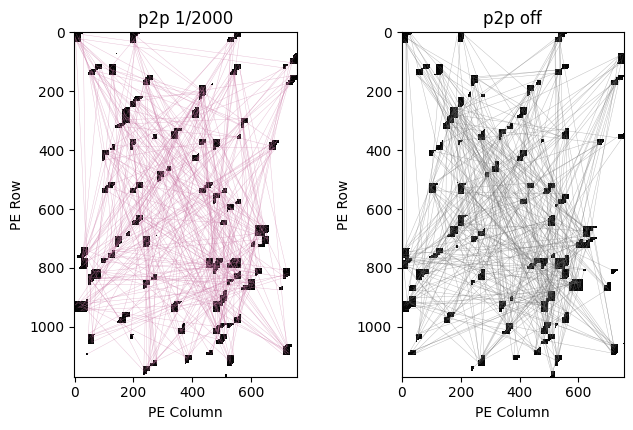

In [ ]:
def coverage_with_partner_links(data, max_links=400):
    _fig, _axes = plt.subplots(
        1, len(RUNS), figsize=(3.4 * len(RUNS), 4.4)
    )
    for _ax, _cfg in zip(
        np.atleast_1d(_axes), config_df.iter_rows(named=True)
    ):
        _run, _ncol, _nrow = _cfg["run"], _cfg["nCol"], _cfg["nRow"]
        _d = data[data["run"] == _run]
        _grid = np.full((_nrow, _ncol), np.nan)
        _grid[_d["row"].to_numpy(), _d["col"].to_numpy()] = _d[
            "num_genomes"
        ].to_numpy()
        _ax.imshow(
            _grid,
            cmap="Greys",
            norm=plt.matplotlib.colors.LogNorm(vmin=1),
            interpolation="nearest",
        )
        # partner links between sampled PEs (a random subset)
        _sampled = np.zeros(_nrow * _ncol, dtype=bool)
        _sampled[_d["row"].to_numpy() * _ncol + _d["col"].to_numpy()] = (
            True
        )
        _partner = partner_maps[_run]
        _src = np.flatnonzero(
            _sampled
            & (_partner >= 0)
            & _sampled[np.where(_partner >= 0, _partner, 0)]
        )
        _src = _src[_src < _partner[_src]]
        _rng = np.random.default_rng(SEED)
        _src = _rng.permutation(_src)[:max_links]
        for _s in _src:
            (_r0, _c0), (_r1, _c1) = divmod(_s, _ncol), divmod(
                _partner[_s], _ncol
            )
            _ax.plot(
                [_c0, _c1],
                [_r0, _r1],
                color=RUN_PALETTE[_run],
                linewidth=0.3,
                alpha=0.5,
            )
        _ax.set_title(_run)
        _ax.set_xlabel("PE Column")
        _ax.set_ylabel("PE Row")
    _fig.tight_layout()

tp.tee(
    coverage_with_partner_links,
    data=pe_counts,
    teeplot_show=True,
    teeplot_subdir=pathlib.Path(__file__).stem,
)
plt.close("all")

In [ ]:
mo.md(f"""
## Spatial Separation of Close Relatives

The distance between the two leaves of each cherry, and between the leaf centroids of each node's two child clades, by the node's age.
Long-distance migration that founds persisting lineages would show up as young sister clades far apart.
The table gives, per age bin, the fraction of sister clade pairs more than {FAR_PES} and more than 200 PEs apart.
""")

## Spatial Separation of Close Relatives

The distance between the two leaves of each cherry, and between the leaf centroids of each node's two child clades, by the node's age.
Long-distance migration that founds persisting lineages would show up as young sister clades far apart.
The table gives, per age bin, the fraction of sister clade pairs more than 50 and more than 200 PEs apart.

teeplots/2026-11-09-mls-indiv-spectra-fullgrid-fossils-kdtree-p2p/hue=run+kind=ecdf+viz=displot+what=cherry-distances+x=distance+ext=.pdf
teeplots/2026-11-09-mls-indiv-spectra-fullgrid-fossils-kdtree-p2p/hue=run+kind=ecdf+viz=displot+what=cherry-distances+x=distance+ext=.png


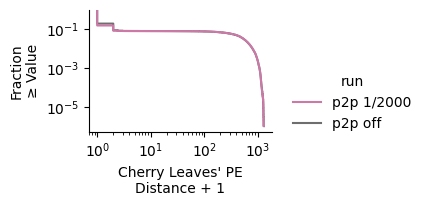

In [ ]:
with tp.teed(
    sns.displot,
    data=sisters[sisters["is_cherry"]].assign(
        distance=lambda df: df["separation"] + 1
    ),
    x="distance",
    hue="run",
    hue_order=[*RUNS],
    palette=RUN_PALETTE,
    kind="ecdf",
    complementary=True,
    log_scale=(True, True),
    height=2.0,
    aspect=1.4,
    teeplot_outattrs={"what": "cherry-distances"},
    teeplot_outexclude=["palette", "hue_order", "log_scale"],
    teeplot_show=True,
    teeplot_subdir=pathlib.Path(__file__).stem,
) as _g:
    _g.set_axis_labels(
        "Cherry Leaves' PE\nDistance + 1", "Fraction\n≥ Value"
    )
plt.close("all")

In [ ]:
age_bins = [0, 100, 300, 1000, 2000, 4000, np.inf]
separation_by_age = (
    sisters.assign(
        age_bin=pd.cut(
            sisters["age"],
            age_bins,
            labels=[
                f"{a:g}–{b:g}" for a, b in zip(age_bins, age_bins[1:])
            ],
        ),
        far=sisters["separation"] > FAR_PES,
        very_far=sisters["separation"] > 200,
    )
    .groupby(["age_bin", "run"], observed=True)
    .agg(
        num_pairs=("separation", "size"),
        frac_far=("far", "mean"),
        frac_very_far=("very_far", "mean"),
    )
    .reset_index()
)
# binomial standard errors, ignoring nesting
for _col in ("frac_far", "frac_very_far"):
    separation_by_age[f"{_col}_se"] = np.sqrt(
        separation_by_age[_col]
        * (1 - separation_by_age[_col])
        / separation_by_age["num_pairs"]
    )
separation_by_age = separation_by_age.sort_values(["age_bin", "run"])
mo.Html(
    separation_by_age.pivot_table(
        index="age_bin",
        columns="run",
        values=["num_pairs", "frac_far", "frac_very_far"],
        observed=True,
    ).to_html(float_format="{:.4g}".format),
)

frac_far 
 frac_very_far 
 num_pairs 
 
 
 run 
 p2p 1/2000 
 p2p off 
 p2p 1/2000 
 p2p off 
 p2p 1/2000 
 p2p off 
 
 
 age_bin 
 
 
 
 
 
 
 
 
 
 
 0–100 
 0.01071 
 0.01032 
 0.009706 
 0.00796 
 7006 
 6784 
 
 
 100–300 
 0.00255 
 0.002131 
 0.002257 
 0.001889 
 7.842e+04 
 7.837e+04 
 
 
 300–1000 
 0.06091 
 0.05925 
 0.05319 
 0.05169 
 5.498e+05 
 5.463e+05 
 
 
 1000–2000 
 0.1051 
 0.1039 
 0.09042 
 0.08918 
 7.76e+05 
 7.721e+05 
 
 
 2000–4000 
 0.1377 
 0.1371 
 0.1148 
 0.1141 
 1.007e+06 
 1.005e+06 
 
 
 4000–inf 
 0.4482 
 0.4489 
 0.3672 
 0.3663 
 1.194e+06 
 1.206e+06

teeplots/2026-11-09-mls-indiv-spectra-fullgrid-fossils-kdtree-p2p/viz=separation-by-age-bin+ext=.pdf
teeplots/2026-11-09-mls-indiv-spectra-fullgrid-fossils-kdtree-p2p/viz=separation-by-age-bin+ext=.png


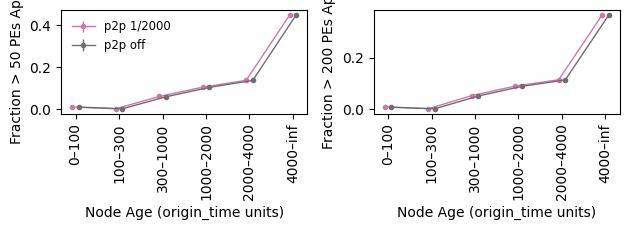

In [ ]:
def separation_by_age_bin(data):
    _fig, _axes = plt.subplots(1, 2, figsize=(6.4, 2.4), sharex=True)
    for _ax, (_col, _label) in zip(
        _axes,
        (
            ("frac_far", f"Fraction > {FAR_PES} PEs Apart"),
            ("frac_very_far", "Fraction > 200 PEs Apart"),
        ),
    ):
        for _j, _run in enumerate(RUNS):
            _d = data[data["run"] == _run]
            _x = np.arange(len(_d)) + (_j - 0.5) * 0.15
            _ax.errorbar(
                _x,
                _d[_col],
                yerr=1.96 * _d[f"{_col}_se"],
                color=RUN_PALETTE[_run],
                marker="o",
                markersize=3,
                linewidth=1,
                label=_run,
            )
        _ax.set_xticks(
            range(data["age_bin"].nunique()),
            data["age_bin"].cat.categories,
            rotation=90,
        )
        _ax.set_ylabel(_label)
        _ax.set_xlabel("Node Age (origin_time units)")
    _axes[0].legend(frameon=False, fontsize="small")
    _fig.tight_layout()

tp.tee(
    separation_by_age_bin,
    data=separation_by_age,
    teeplot_show=True,
    teeplot_subdir=pathlib.Path(__file__).stem,
)
plt.close("all")

In [ ]:
mo.md(f"""
## Partner-alignment Test

A p2p migrant lands on its sender's partner PE, so a lineage it founds starts out next to that partner, far from the sender's relatives.
So, among far-apart (> {FAR_PES} PEs) sister clade pairs whose clades are each spatially compact (rms spread ≤ {COMPACT_PES} PEs), this test counts how many are linked by a p2p partnership: some PE within a radius of one clade's centroid is partnered with a PE within that radius of the other's.

How often this happens by chance depends on where the sampled patches lie, so the null comes from the same sister pairs scored against {NUM_NULL_MAPS} random partner maps.
The p2p-off run is scored against its own seed's partner map, which its run never used, as a negative control.
""")

## Partner-alignment Test

A p2p migrant lands on its sender's partner PE, so a lineage it founds starts out next to that partner, far from the sender's relatives.
So, among far-apart (> 50 PEs) sister clade pairs whose clades are each spatially compact (rms spread ≤ 5 PEs), this test counts how many are linked by a p2p partnership: some PE within a radius of one clade's centroid is partnered with a PE within that radius of the other's.

How often this happens by chance depends on where the sampled patches lie, so the null comes from the same sister pairs scored against 50 random partner maps.
The p2p-off run is scored against its own seed's partner map, which its run never used, as a negative control.

In [ ]:
_rows, _nulls = [], []
for _cfg in config_df.iter_rows(named=True):
    _run, _nrow, _ncol = _cfg["run"], _cfg["nRow"], _cfg["nCol"]
    _cand = sisters[
        (sisters["run"] == _run)
        & (sisters["separation"] > FAR_PES)
        & (sisters["spread_a"] <= COMPACT_PES)
        & (sisters["spread_b"] <= COMPACT_PES)
    ]
    for _radius in PARTNER_RADII:
        _hits = count_partner_hits(
            _cand, partner_maps[_run], _nrow, _ncol, _radius
        )
        _null = np.array(
            [
                count_partner_hits(
                    _cand,
                    make_partner_map(10_000 + _k, _nrow, _ncol),
                    _nrow,
                    _ncol,
                    _radius,
                ).sum()
                for _k in range(NUM_NULL_MAPS)
            ],
        )
        _young = _cand["age"].to_numpy() <= 1000
        _rows.append(
            {
                "run": _run,
                "radius": _radius,
                "num_pairs": len(_cand),
                "observed_hits": int(_hits.sum()),
                "null_mean": _null.mean(),
                "null_sd": _null.std(ddof=1),
                "z": (_hits.sum() - _null.mean()) / _null.std(ddof=1),
                "empirical_p": (1 + (_null >= _hits.sum()).sum())
                / (1 + len(_null)),
                "num_young_pairs": int(_young.sum()),
                "observed_young_hits": int(_hits[_young].sum()),
            },
        )
        _nulls.append(
            pd.DataFrame(
                {"run": _run, "radius": _radius, "null_hits": _null}
            )
        )
partner_test = pd.DataFrame(_rows)
partner_test_nulls = pd.concat(_nulls, ignore_index=True)
mo.Html(partner_test.to_html(float_format="{:.4g}".format, index=False))

run,radius,num_pairs,observed_hits,null_mean,null_sd,z,empirical_p,num_young_pairs,observed_young_hits
p2p 1/2000,3,292208,634,657,21.93,-1.049,0.902,29473,57
p2p 1/2000,5,292208,4284,4227,92.07,0.6156,0.2941,29473,455
p2p off,3,291436,656,649.9,30.63,0.1978,0.4314,28453,78
p2p off,5,291436,4196,4200,85.71,-0.04667,0.5882,28453,395


teeplots/2026-11-09-mls-indiv-spectra-fullgrid-fossils-kdtree-p2p/viz=partner-hits-vs-null+ext=.pdf
teeplots/2026-11-09-mls-indiv-spectra-fullgrid-fossils-kdtree-p2p/viz=partner-hits-vs-null+ext=.png


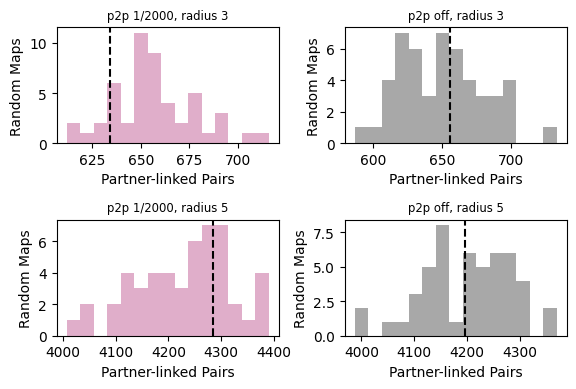

In [ ]:
def partner_hits_vs_null(data, observed):
    _fig, _axes = plt.subplots(
        len(PARTNER_RADII),
        len(RUNS),
        figsize=(3.0 * len(RUNS), 2.0 * len(PARTNER_RADII)),
        squeeze=False,
    )
    for _i, _radius in enumerate(PARTNER_RADII):
        for _j, _run in enumerate(RUNS):
            _ax = _axes[_i, _j]
            _d = data[(data["run"] == _run) & (data["radius"] == _radius)]
            _ax.hist(
                _d["null_hits"],
                bins=15,
                color=RUN_PALETTE[_run],
                alpha=0.6,
            )
            _obs = observed[
                (observed["run"] == _run) & (observed["radius"] == _radius)
            ]["observed_hits"].item()
            _ax.axvline(_obs, color="black", linestyle="--")
            _ax.set_title(f"{_run}, radius {_radius}", fontsize="small")
            _ax.set_xlabel("Partner-linked Pairs")
            _ax.set_ylabel("Random Maps")
    _fig.tight_layout()

tp.tee(
    partner_hits_vs_null,
    data=partner_test_nulls,
    observed=partner_test,
    teeplot_outexclude=["observed"],
    teeplot_show=True,
    teeplot_subdir=pathlib.Path(__file__).stem,
)
plt.close("all")

### Notes

- **No detectable evidence of long-distance migration.** Far-apart, compact sister clades in the p2p run sit on p2p partner PEs no more often than under random partner maps ($z \approx -1.0$ at radius 3 and $0.6$ at radius 5), the same as in the p2p-off control, scored against a partner map its run never used ($z \approx 0.2$ and $0.0$).
- **Separation by age is about the same in both runs.** The p2p run has slightly more sister clade pairs more than 200 PEs apart in each age bin up to 4,000 (e.g., 5.32% vs. 5.17% at ages 300–1,000), but by under 0.4 percentage points, which could come from the runs' different seeds and sampled patches; nested pairs are not independent, so the binomial error bars understate the uncertainty.
- **Far-apart cherries are equally common in both runs** (about 7.8% more than 50 PEs apart), mostly old, so they reflect reconstruction and patch layout rather than p2p.
- **Low power is expected here.** Of about 1.8M p2p sends in the run, only about 6,800 link two sampled PEs, as the k-d tree sample covers about 6% of PEs, and a partner of a sampled PE is sampled with about that chance.
  Each immigrant is one genome among 1,133 hosts, so few of these founded lineages long enough to be sampled at both ends.
- Detecting p2p migration would need sampling designed around it, e.g., sampling sender–partner PE pairs together, or many more cycles or a higher send probability.